In [1]:
import torch
import torch.nn
import copy
import matplotlib.pyplot as plt

from laya.pretrained import PretrainedDecisionModel
from laya.sft import evaluate
from laya.decision_reward import downstream_reward
from laya.grpo import grpo_step, generate_rollout
from laya.dataset import (
    raw_examples,
    LABELS,
    build_decision_examples,
    move_batch_to_device,
    encode_decision_batch,
)

from transformers import AutoTokenizer
import random

device = "cpu"

/Users/van/Documents/Van/Code/laya-from-scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
model_name = "bert-base-uncased"

In [3]:
sft_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
sft_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)
sft_model = sft_model.to(device)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23325.78it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [4]:
reference_model = copy.deepcopy(sft_model)

reference_model.eval()  # no train
for para in reference_model.parameters():
    para.requires_grad = False

In [5]:
# train data
tokenizer = AutoTokenizer.from_pretrained(model_name)

examples = build_decision_examples(raw_examples, LABELS, seed=42)

# train valid split
rng = random.Random(123)

indices = list(range(len(examples)))
rng.shuffle(indices)

cut = 48
train_indices = indices[:cut]
validate_indices = indices[cut:]

train_examples = [examples[e] for e in train_indices]
validate_examples = [examples[e] for e in validate_indices]

train_batch = encode_decision_batch(train_examples, tokenizer)
validate_batch = encode_decision_batch(validate_examples, tokenizer)

train_targets = torch.tensor(
    [e["target"] for e in train_examples], dtype=torch.long
).to(device)
validate_targets = torch.tensor(
    [e["target"] for e in validate_examples], dtype=torch.long
).to(device)

train_batch = move_batch_to_device(train_batch, device)
validate_batch = move_batch_to_device(validate_batch, device)

decision head only


In [6]:
grpo_model = copy.deepcopy(sft_model)

for para in grpo_model.backbone.parameters():
    para.requireds_grad = False

In [7]:
optimizer = torch.optim.AdamW(grpo_model.decision_head.parameters(), lr=1e-5)

In [8]:
loss_history = []
policy_loss_history = []
kl_history = []
reward_history = []

n_rollouts = 100
updates_per_rollout = 3


for step in range(n_rollouts):
    rollout = generate_rollout(
        grpo_model,
        train_batch["input_ids"],
        train_batch["attention_mask"],
        train_batch["option_marker_mask"],
        train_targets,
        n_candidates=32,
        exploration_std=0.2,
        scoring_weight=0.5,
    )

    reward_history.append(rollout["rewards"].mean().item())

    for update in range(updates_per_rollout):
        loss, policy, kl = grpo_step(
            grpo_model,
            reference_model,
            optimizer,
            train_batch["input_ids"],
            train_batch["attention_mask"],
            train_batch["option_marker_mask"],
            rollout,
            exploration_std=0.2,
            clip_epsilon=0.2,
            kl_beta=0.01,
        )

        loss_history.append(loss)
        policy_loss_history.append(policy)
        kl_history.append(kl)

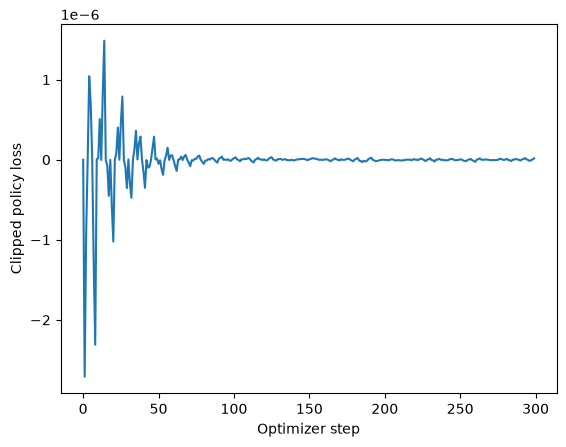

In [9]:
plt.figure()

plt.plot(
    policy_loss_history,
)

plt.xlabel("Optimizer step")
plt.ylabel("Clipped policy loss")

plt.show()

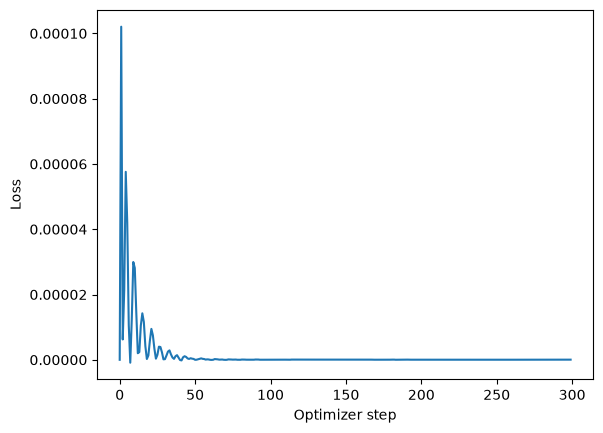

In [10]:
plt.figure()

plt.plot(
    loss_history,
)

plt.xlabel("Optimizer step")
plt.ylabel("Loss")

plt.show()

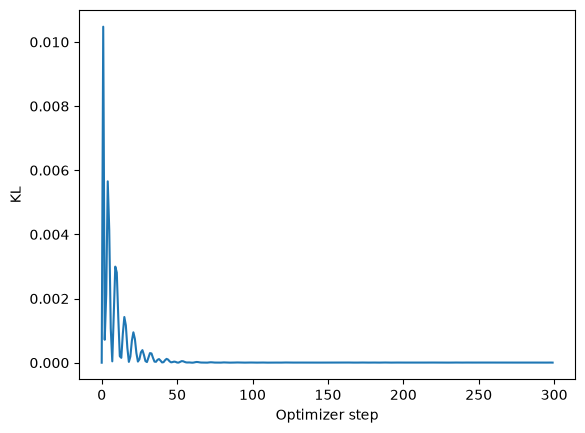

In [11]:
plt.figure()

plt.plot(
    kl_history,
)

plt.xlabel("Optimizer step")
plt.ylabel("KL")

plt.show()

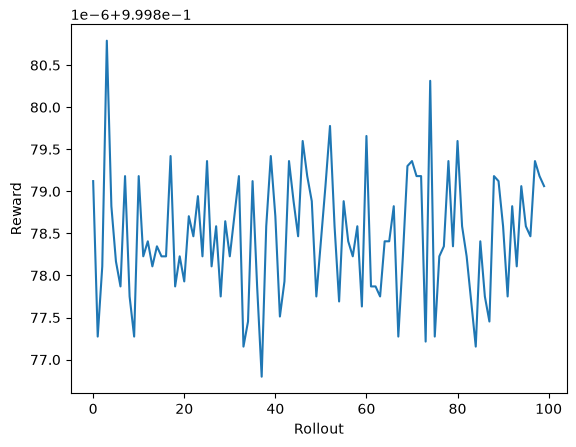

In [12]:
plt.figure()

plt.plot(
    reward_history,
)

plt.xlabel("Rollout")
plt.ylabel("Reward")

plt.show()

In [13]:
before_loss, before_accuracy, before_probabilities = evaluate(
    model=sft_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)

before_utility = (
    downstream_reward(
        before_probabilities,
        validate_targets,
    )
    .mean()
    .item()
)

In [14]:
after_loss, after_accuracy, after_probabilities = evaluate(
    model=grpo_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)


after_utility = (
    downstream_reward(
        after_probabilities,
        validate_targets,
    )
    .mean()
    .item()
)

In [15]:
print(f"{'Metric':<20}" f"{'SFT':>12}" f"{'GRPO':>12}")

print(f"{'Accuracy':<20}" f"{before_accuracy:>12.4f}" f"{after_accuracy:>12.4f}")

print(f"{'NLL':<20}" f"{before_loss:>12.4f}" f"{after_loss:>12.4f}")

print(f"{'Utility':<20}" f"{before_utility:>12.4f}" f"{after_utility:>12.4f}")

Metric                       SFT        GRPO
Accuracy                  0.5833      0.5833
NLL                       1.7699      1.7698
Utility                  -0.3750     -0.3750
